# Visualization of runs

In [24]:
import altair as alt
import pandas as pd
from pathlib import Path
import json
alt.data_transformers.enable("vegafusion")

DataTransformerRegistry.enable('vegafusion')

In [25]:


results_dirs_model_size = {
    'strides': Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/strides"),
    'num_prompts': Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/num_prompts"),
    'model_sizes': Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/model_sizes"),
    "baseline": Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/baseline"),
    'confidence_gating': Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/confidence_gating"),
    'memory_bank': Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/memory_bank"),
    "axis_modes": Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/axis_modes"),
    "conditioned_selection": Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/conditioned_selection"),
    "preprocessing": Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/preprocessing"),
    "conditional_frame_selection": Path("/home/sam2group/Sam2/ML-P2-Sam2/outputs/evaluations/conditional_frame_selection"),

}

def load_results_from_dirs(results_dirs):
    # Store all results here
    individual_results = []
    for category, results_dir in results_dirs.items():
        if not results_dir.exists():
            print(f"warning: missing directory {results_dir}")
            continue

        for path in sorted(results_dir.glob("*.json")):
            try:
                with path.open("r") as f:
                    result_dict = json.load(f)
            except json.JSONDecodeError:
                print(f"warning: could not parse {path}")
                continue

            label = path.stem
            for individual_result in result_dict.get("individual_results", []):
                if "error" in individual_result:
                    print("warning: error in individual_result")
                    continue

                # add explicit category and label fields
                individual_result = {
                    "category": label,
                    "eval_category": category,
                    "mean_dice": individual_result["mean_dice"],
                    "mean_iou": individual_result["mean_iou"],
                    "bone": individual_result["bone_name"],
                }
                individual_results.append(individual_result)

    # Create DataFrame and only keep if mean_dice is present
    df = pd.DataFrame(individual_results)
    df = df[df["mean_dice"].notna()]
    return df
df = load_results_from_dirs( results_dirs_model_size)
# have value, metric, category, eval_category
df = df.melt(id_vars=["category", "eval_category", "bone"], var_name="metric", value_name="value")
df.head()


,category,eval_category,bone,metric,value
0,stride_2,strides,sacrum,mean_dice,0.667918
1,stride_2,strides,vertebrae,mean_dice,0.651127
2,stride_2,strides,vertebrae,mean_dice,0.589413
3,stride_2,strides,sacrum,mean_dice,0.781692
4,stride_2,strides,vertebrae,mean_dice,0.595940


In [ ]:
# 1. Compute stats for ALL categories and metrics in a single DataFrame
grouped = df.groupby(['eval_category', 'category', 'metric'])['value']
df_stats = grouped.agg(['mean', 'std']).reset_index()

# Rename 'mean' to 'value' to match your preference
df_stats = df_stats.rename(columns={'mean': 'value'})

# 2. Iterate through each metric type to display one table per metric
unique_metrics = df_stats['metric'].unique()

for metric in unique_metrics:
    print(f"--- Results for: {metric} ---")
    
    # Filter for the current metric
    df_metric_view = df_stats[df_stats['metric'] == metric].copy()
    
    # Sort by value (mean) descending
    df_metric_view = df_metric_view.sort_values('value', ascending=False)
    
    # Set index for a cleaner "grouped" visual display
    display(df_metric_view.set_index(['eval_category', 'category']))

    print(df_metric_view)

In [ ]:
eval_categories = list(results_dirs_model_size.keys())
for cat in eval_categories:
    # Filter the DataFrame for the current eval_category
    df_cat = df[df['eval_category'] == cat]
    # Compute mean and std together, maintaining correct order
    grouped = df_cat.groupby(['category', 'metric'])['value']
    df_cat_stats = grouped.agg(['mean', 'std']).reset_index()
    df_cat_stats = df_cat_stats.rename(columns={'mean': 'value'})
    # Sort by mean value
    df_cat_stats = df_cat_stats.sort_values('value', ascending=False)
    # Split by metric for display
    df_cat_iou = df_cat_stats[df_cat_stats['metric'] == 'mean_iou']
    df_cat_dice = df_cat_stats[df_cat_stats['metric'] == 'mean_dice']
    print(df_cat_iou)
    print(df_cat_dice)

   category    metric     value       std
3  stride_4  mean_iou  0.763474  0.135204
1  stride_2  mean_iou  0.755583  0.141163
   category     metric     value       std
2  stride_4  mean_dice  0.827106  0.119017
0  stride_2  mean_dice  0.818899  0.126746
            category    metric     value       std
7  middle_last_end_4  mean_iou  0.783071  0.128861
5  middle_last_end_2  mean_iou  0.758584  0.148580
1         first_last  mean_iou  0.721394  0.191373
3             middle  mean_iou  0.553626  0.225882
            category     metric     value       std
6  middle_last_end_4  mean_dice  0.839451  0.117464
4  middle_last_end_2  mean_dice  0.821683  0.135851
0         first_last  mean_dice  0.788928  0.176829
2             middle  mean_dice  0.608583  0.234526
  category    metric     value       std
3    large  mean_iou  0.763819  0.133367
1     base  mean_iou  0.747831  0.135847
5     tiny  mean_iou  0.740237  0.163350
  category     metric     value       std
2    large  mean_dice  0

In [18]:

# Compute median value for each category for sorting
sorted_categories = (
    df.groupby('category')['value'].median()
    .sort_values(ascending=False)
    .index.tolist()
)

# Create chart with sorted x-axis by median
schart = alt.Chart(df).mark_boxplot(extent='min-max').encode(
    y='value',
    x=alt.X('category:N', sort=sorted_categories),
    column=alt.Column('metric:N')
).properties(
    width=600,
    height=400,
)
schart


alt.Chart(...)

In [20]:
# Create a boxplot chart for mean_iou scores, grouped by bone and metric for each category
# extent  quantiles
# Rows: bone types, Columns: metric (though only mean_iou is shown), X-axis: model category
df_iou = df[df['metric'] == 'mean_iou']
df_dice = df[df['metric'] == 'mean_dice']

chart_iou = (
    alt.Chart(df_iou)
    .mark_boxplot()
    .encode(
        x=alt.X('category:N', title='Model Category', sort=sorted_categories),
        y=alt.Y('value:Q', title='Mean IoU Value', scale=alt.Scale(domain=[0.1, 1])),
        row=alt.Row('bone:N', title='Bone Type'),
        column=alt.Column('metric:N', title='Metric')
    )
    .properties(width=800, height=200)
    .configure_axis(
        labelFontSize=12,
        titleFontSize=14
    )
    .configure_header(
        titleFontSize=14,
        labelFontSize=12
    )
)
chart_dice = (
        alt.Chart(df_dice)
    .mark_boxplot()
    .encode(
        x=alt.X('category:N', title='Model Category', sort=sorted_categories),
        y=alt.Y('value:Q', title='Mean IoU Value', scale=alt.Scale(domain=[0.1, 1])),
        row=alt.Row('bone:N', title='Bone Type'),
        column=alt.Column('metric:N', title='Metric')
    )
    .properties(width=800, height=200)
    .configure_axis(
        labelFontSize=12,
        titleFontSize=14
    )
    .configure_header(
        titleFontSize=14,
        labelFontSize=12
    )
)

chart_iou

alt.Chart(...)

In [26]:
# Heatmap with per-cell mean, text; mark the top 3 values per bone with different styles/colors/weight
def add_rank_marker(df_mean):
    df_best = df_mean.copy()
    df_best['rank'] = 4  # default: not top 3

    for bone in df_best['bone'].unique():
        bone_rows = df_best[df_best['bone'] == bone]
        top_indices = bone_rows['value'].rank(method='first', ascending=False)
        # Assign 1 to best, 2 to second-best, 3 to third-best
        for rank in [1, 2, 3]:
            mask = (df_best['bone'] == bone) & (top_indices == rank)
            df_best.loc[mask, 'rank'] = rank

    return df_best

ioum = df[df['metric'] == 'mean_iou'].groupby(['category', 'bone'], as_index=False)['value'].mean()
ioum = add_rank_marker(ioum)

dicem = df[df['metric'] == 'mean_dice'].groupby(['category', 'bone'], as_index=False)['value'].mean()
dicem = add_rank_marker(dicem)

def make_heatmap_with_overall_column(dfm, title):
    # Compute overall mean for each category and sort y by this mean (descending)
    categories = dfm['category'].unique()
    # Will compute bone order by overall mean value, descending. "Overall" last.
    bone_means = (
        dfm.groupby('bone')['value']
        .mean()
        .sort_values(ascending=False)
    )
    all_bones = list(bone_means.index) + ['Overall']

    means = (
        dfm.groupby('category')['value']
        .mean()
        .reset_index()
        .assign(bone='Overall')
    )
    means['rank'] = 0  # So overall is not highlighted

    dfm_wide = pd.concat([dfm, means], ignore_index=True)

    # Now sort categories by mean (descending) for y-axis
    cat_order = (
        dfm_wide[dfm_wide['bone'] == 'Overall'][['category', 'value']]
        .sort_values('value', ascending=False)['category']
        .tolist()
    )

    color_expr = (
        "datum.rank == 1 ? '#ff3333' : "
        "datum.rank == 2 ? '#ff9900' : "
        "datum.rank == 3 ? '#3399ff' : "
        "datum.bone == 'Overall' ? '#eeeeee' : 'white'"
    )
    fontweight_expr = (
        "datum.rank == 1 ? 'bold' : "
        "datum.rank == 2 ? 'bold' : "
        "datum.rank == 3 ? 'bold' : "
        "datum.bone == 'Overall' ? 'bold' : 'normal'"
    )

    base = alt.Chart(dfm_wide).mark_rect(opacity=0.7).encode(
        x=alt.X('bone:N', title='Bone', sort=all_bones),
        y=alt.Y('category:N', title='Category',
                sort=cat_order),  # Now sorted by overall mean value!
        color=alt.Color('value:Q', scale=alt.Scale(scheme='viridis')),
    ).properties(width=50 * len(all_bones), height=600, title=title)

    text = alt.Chart(dfm_wide).mark_text(
        fontSize=18,
        fontWeight=alt.ExprRef(fontweight_expr),
        color=alt.ExprRef(color_expr),
        baseline='middle'
    ).encode(
        x=alt.X('bone:N', sort=all_bones),
        y=alt.Y('category:N', sort=cat_order),
        text=alt.Text('value:Q', format='.3f'),
        detail='rank:N',
    )

    return base + text

make_heatmap_with_overall_column(ioum, 'mean_iou') | make_heatmap_with_overall_column(dicem, 'mean_dice')

alt.HConcatChart(...)

In [22]:
# Show metric mean dice ordered descending by mean, grouped by eval_category, in a nicely formatted DataFrame
mean_df = (
    df.groupby(['category', 'metric', 'eval_category'])['value']
    .mean()
    .reset_index()
    .sort_values(by='value', ascending=False)
)
display(mean_df[mean_df['metric'] == 'mean_dice'])
display(mean_df[mean_df['metric'] == 'mean_iou'])


,category,metric,eval_category,value
50,three_axis,mean_dice,axis_modes,0.866119
28,middle_last_end_4,mean_dice,num_prompts,0.839451
14,gate_3,mean_dice,confidence_gating,0.829657
48,test_with_margin,mean_dice,conditioned_selection,0.829478
12,gate_2,mean_dice,confidence_gating,0.829083
22,large,mean_dice,model_sizes,0.829064
10,gate_1,mean_dice,confidence_gating,0.828670
16,gate_4,mean_dice,confidence_gating,0.827686
46,stride_4,mean_dice,strides,0.827106
18,gate_5,mean_dice,confidence_gating,0.824485


,category,metric,eval_category,value
51,three_axis,mean_iou,axis_modes,0.800343
29,middle_last_end_4,mean_iou,num_prompts,0.783071
15,gate_3,mean_iou,confidence_gating,0.766373
13,gate_2,mean_iou,confidence_gating,0.765747
11,gate_1,mean_iou,confidence_gating,0.765351
17,gate_4,mean_iou,confidence_gating,0.764449
23,large,mean_iou,model_sizes,0.763819
47,stride_4,mean_iou,strides,0.763474
49,test_with_margin,mean_iou,conditioned_selection,0.761496
19,gate_5,mean_iou,confidence_gating,0.761409


In [ ]:
# get table with model_size, num_succesful_cases, dice_mean pm std, iou_mean pm std, dice_min, iou_min, dice_max, iou_max
results_df_selection = results_agg_df[['num_successful_cases', 'dice_mean', 'dice_std', 'iou_mean', 'iou_std', 'dice_min', 'iou_min', 'dice_max', 'iou_max']]
results_df_selection

,num_successful_cases,dice_mean,dice_std,iou_mean,iou_std,dice_min,iou_min,dice_max,iou_max
0,193.0,0.840791,0.159115,0.781999,0.168423,0.0,0.0,0.973484,0.951988
1,193.0,0.851400,0.136260,0.792524,0.149477,0.0,0.0,0.973027,0.950669
2,192.0,0.846262,0.132860,0.784946,0.146925,0.0,0.0,0.970332,0.946996
3,193.0,0.851015,0.135765,0.789729,0.147236,0.0,0.0,0.975646,0.954300


In [3]:
import json

In [ ]:
def find_best_improvement_cases(json_path1: str, json_path2: str, top_n: int = 10, metric: str = "mean_dice"):
    """
    Find cases where the first output JSON performs much better than the second.
    
    Args:
        json_path1: Path to first results JSON (the "better" one)
        json_path2: Path to second results JSON (the "worse" one)
        top_n: Number of top cases to return
        metric: Metric to compare ("mean_dice", "mean_iou", or "mean_hausdorff")
    
    Returns:
        DataFrame with cases sorted by improvement (first - second)
    """
    with open(json_path1) as f:
        data1 = json.load(f)
    with open(json_path2) as f:
        data2 = json.load(f)
    results1 = {(r["case_name"], r.get("bone_name", ""), r["case_index"]): r 
                for r in data1["individual_results"] if r.get(metric) is not None}
    results2 = {(r["case_name"], r.get("bone_name", ""), r["case_index"]): r 
                for r in data2["individual_results"] if r.get(metric) is not None}
    
    common_keys = set(results1.keys()) & set(results2.keys())
    
    print(f"Found {len(common_keys)} common cases")
    comparisons = []
    for key in common_keys:
        r1, r2 = results1[key], results2[key]
        val1, val2 = r1[metric], r2[metric]
        # For hausdorff, lower is better, so invert
        if metric == "mean_hausdorff":
            diff = val2 - val1  # positive = first is better
        else:
            diff = val1 - val2  # positive = first is better
        comparisons.append({
            "case_name": key[0],
            "bone_name": key[1],
            "case_index": key[2],
            f"{metric}_1": val1,
            f"{metric}_2": val2,
            "improvement": diff
        })
    
    df = pd.DataFrame(comparisons).sort_values("improvement", ascending=False)
    return df

find_best_improvement_cases(
    "../outputs/evaluations/combined/temp_thres_gate_3.json",
    "../outputs/evaluations/preprocessing/no_clahe_windowing.json",
    2
)

Found 491 common cases


,case_name,bone_name,case_index,mean_dice_1,mean_dice_2,improvement
453,ct.nii,rib,426,0.816312,0.116993,0.699319
421,ct.nii,sacrum,27,0.701676,0.046478,0.655198
166,ct.nii,sacrum,43,0.893116,0.431115,0.462002
230,ct.nii,rib,441,0.919000,0.481614,0.437386
486,ct.nii,rib,434,0.828357,0.437218,0.391139
...,...,...,...,...,...,...
241,ct.nii,rib,418,0.364885,0.539429,-0.174544
27,ct.nii,rib,406,0.387029,0.571652,-0.184623
222,ct.nii,rib,414,0.590319,0.808996,-0.218677
480,ct.nii,rib,416,0.599741,0.839244,-0.239503


: 

final_image_files: ['slice_0098.png', 'slice_0099.png', 'slice_0100.png', 'slice_0101.png', 'slice_0102.png', 'slice_0103.png', 'slice_0104.png', 'slice_0105.png', 'slice_0106.png', 'slice_0107.png', 'slice_0108.png', 'slice_0109.png', 'slice_0110.png', 'slice_0111.png', 'slice_0112.png', 'slice_0113.png']


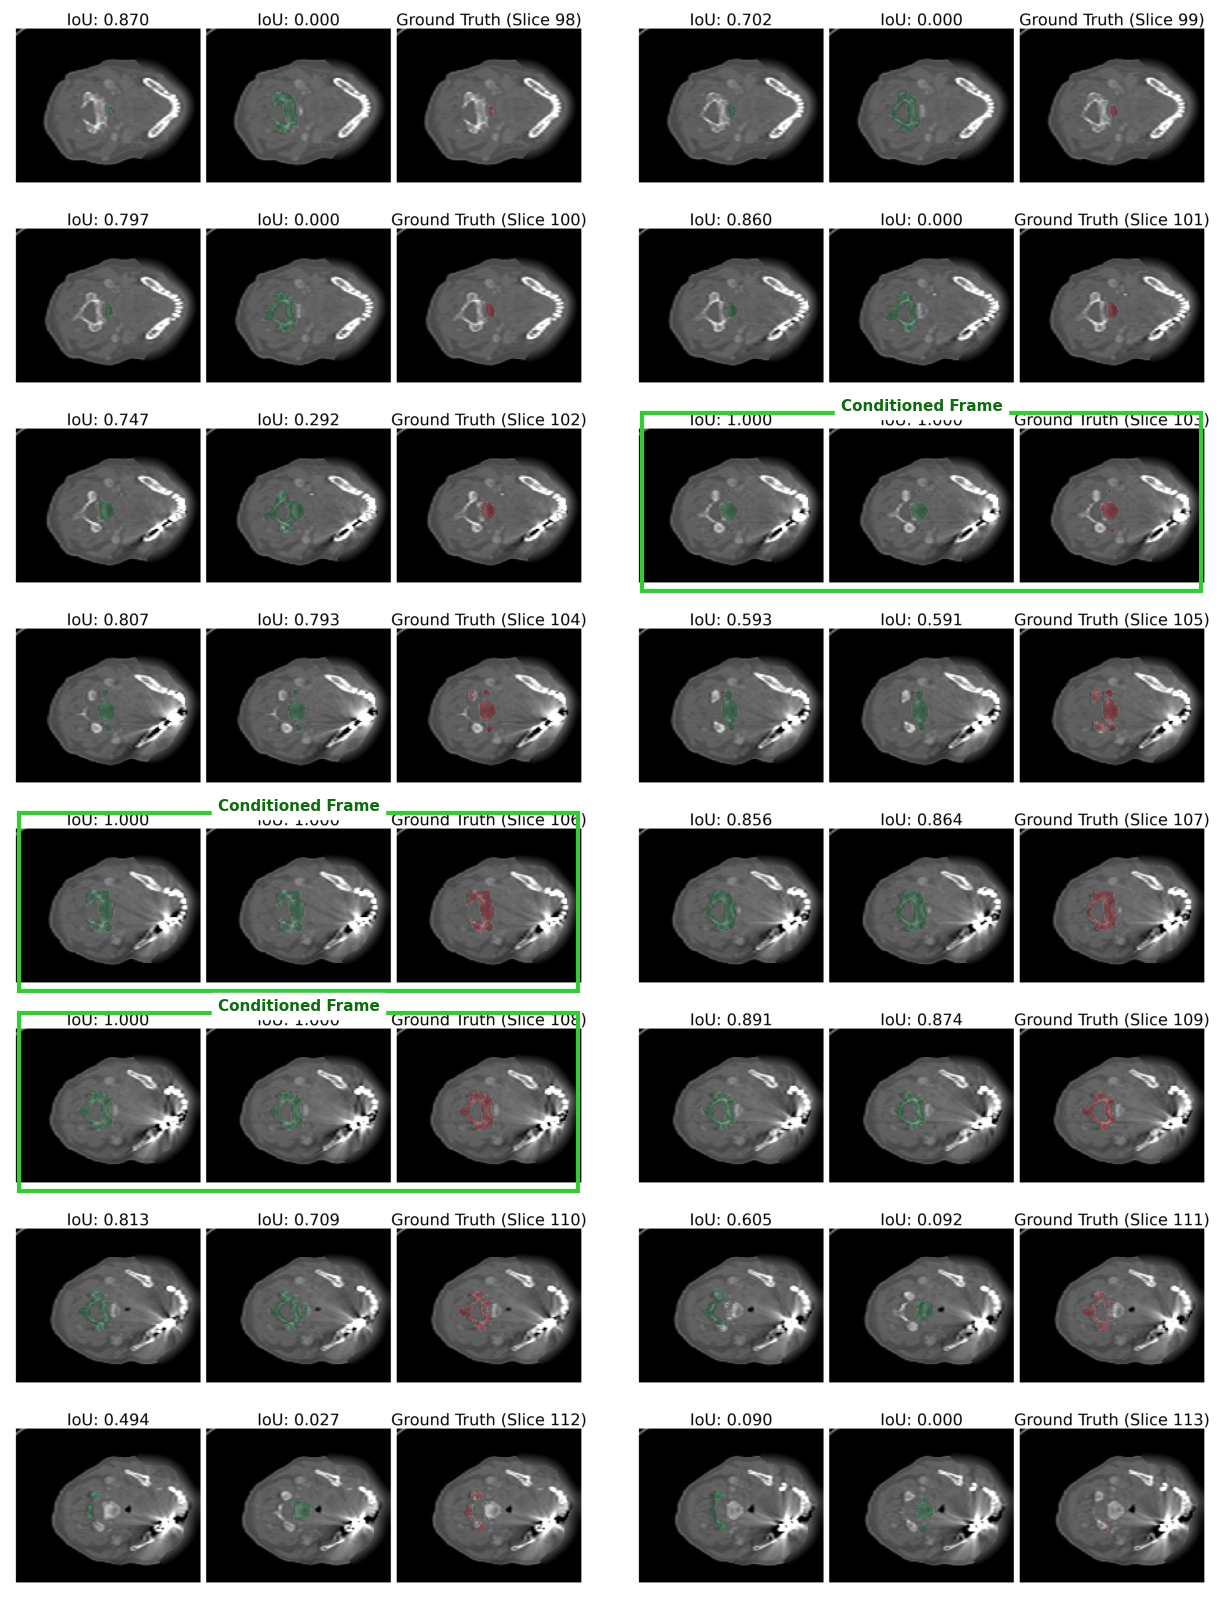

In [41]:
from matplotlib import pyplot as plt
import os
import matplotlib.patches as patches
import math

# Directory containing the comparison output (change as needed)
comparison_dir = "/home/sam2group/Sam2/ML-P2-Sam2/outputs/comparison/20251217_123148/vertebrae/ct.nii_vertebrae_C3.nii"

# Indices of prompted frames
# prompted_idxs = [103, 106, 108]

def extract_idx(fname):
    base = os.path.splitext(fname)[0]
    if base.startswith("slice_0"):
        try:
            return int(base.replace("slice_0", ""))
        except ValueError:
            return None
    return None

prompted_idxs = [103, 106, 108]

# List all image files and collect indices
image_files = [f for f in os.listdir(comparison_dir) if f.startswith("slice_0") and f.endswith(".png")]
idx_to_file = {}
for f in image_files:
    idx = extract_idx(f)
    if idx is not None:
        idx_to_file[idx] = f

# Now all available indices for plotting
present_idxs = sorted(idx_to_file.keys())

# Always include all present frames, and highlight prompts if among them
final_idxs = present_idxs

final_image_files = [idx_to_file[idx] for idx in final_idxs]

n_images = len(final_image_files)
n_cols = 2
n_rows = math.ceil(n_images / n_cols)

# Compute aspect ratio and appropriate size
if final_image_files:
    first_img_path = os.path.join(comparison_dir, final_image_files[0])
    first_img = plt.imread(first_img_path)
    img_height, img_width = first_img.shape[:2]
    aspect = img_width / img_height
    fig_width = 6  # width for each column
    fig_height_per_img = fig_width / aspect
    fig_height = n_rows * fig_height_per_img
    fig_width_total = n_cols * fig_width
else:
    fig_width_total = 12
    fig_height = 6

wspace = 0.08  # visible separation between columns

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(fig_width_total, fig_height),
    gridspec_kw=dict(hspace=0, wspace=wspace, top=1, bottom=0, left=0, right=1)
)

if n_rows == 1:
    axes = axes.reshape(-1)
else:
    axes = axes.flatten()

title_space = 0.04  # fraction of axes height reserved for title above conditioned frames
print(f"final_image_files: {final_image_files}")
for i, fname in enumerate(final_image_files):
    ax = axes[i]
    idx = extract_idx(fname)
    img_path = os.path.join(comparison_dir, fname)
    img = plt.imread(img_path)

    is_prompt = idx in prompted_idxs
    this_title_space = title_space if is_prompt else 0.0

    ax.imshow(img)
    ax.axis('off')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.margins(0)

    if is_prompt:
        # green background (fills whole axes)
        rect = patches.Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                                 color='limegreen', alpha=0.32, zorder=-2)
        ax.add_patch(rect)

        # add border inside axes, with padding (as fraction of axes dimensions)
        v_pad = 0.015
        h_pad = 0.015
        border_top = v_pad + this_title_space
        border = patches.Rectangle(
            (h_pad, border_top), 1 - 2 * h_pad, 1 - 2 * v_pad - this_title_space,
            linewidth=3, edgecolor='limegreen', facecolor='none',
            transform=ax.transAxes, zorder=3
        )
        ax.add_patch(border)

        # Add text at top, centered, just above border
        ax.text(0.5, 1 - 0.5 * this_title_space,
                "Conditioned Frame",
                fontsize=11, color='darkgreen',
                ha='center', va='bottom',
                transform=ax.transAxes,
                weight='bold',
                zorder=5,
                backgroundcolor='white', alpha=0.95 if this_title_space else 0.8
               )

# Hide any unused axes if number of images is not a multiple of n_cols
for j in range(len(final_image_files), len(axes)):
    axes[j].axis('off')

plt.subplots_adjust(left=0, right=1, top=1, bottom=0, hspace=0, wspace=wspace)
fig.patch.set_alpha(0)
plt.margins(0, 0)
plt.show()
